*  DSC640-T302 Data Presentation & Visualization (2267-1)
*  Weeks 3 & 4 Assignment - White House Logs
*  David Jorgensen

# Weeks 3 & 4 Assignment - White House Logs

---
# The People's House, Reopened
### A three-year look at who came back to the White House (2021–2023)

| | |
|---|---|
| **Audience** | The **White House Visitors Office leadership** and the Chief Usher's staff: internal stakeholders who plan tour capacity, scheduling, and seasonal staffing. They know the WAVES data well, so the briefing stays high-level and jargon-light, leading with the trend and the decision rather than the table. |
| **Purpose / Call to Action** | **Approve a permanent expansion of weekday public-tour capacity and pre-budget surge staffing for the Nov–Dec and May–Jul peaks.** Demand has not just recovered from the COVID shutdown: it has grown roughly 20× since 2021 and is now overwhelmingly tour-driven. The ask is concrete: lock in the larger tour footprint for FY-2024 instead of re-approving it month to month. |
| **Medium** | A **one-page executive briefing / infographic panel** (a cohesive set of charts sharing one visual identity), delivered as this notebook exported to PDF. The written call to action travels with the visuals in the closing summary. |

**Bottom line up front:** White House visitor records grew roughly **20× between 2021 and 2023**, and **public tours, near zero during the shutdown, now make up the majority of every month's traffic**, spiking hard each December and summer.


In [ ]:
# --- Setup & briefing visual identity (applied to every figure) -------------

# Libraries
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
warnings.filterwarnings("ignore")

# Set global style parameters
TOUR  = "#C8A04B"   # public tours       -> White House gold
BIZ   = "#3C5A77"   # official business  -> slate blue
TOTAL = "#2B2B2B"   # combined total     -> near-black
FLAG  = "#B22234"   # call-outs          -> flag red
GRID  = "#E3E3E3"
plt.rcParams.update({
    "figure.figsize": (11, 5.5), "figure.dpi": 110,
    "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelsize": 11, "axes.edgecolor": "#9A9A9A", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "figure.facecolor": "white", "axes.facecolor": "white",
})
thousands = FuncFormatter(lambda x, _: f"{x:,.0f}")
os.makedirs("figures", exist_ok=True)


In [2]:
# --- Load & combine the 25 monthly WAVES files -----------------------------
# The files ship in two header dialects (UPPER_SNAKE through 2022.05, then
# "Title Case" from 2022.06 on) but share an IDENTICAL 27-column layout, so we
# standardize by column position rather than by name.
CANON = ["last","first","mid","uin","bdg","access_type","toa","poa","tod","pod",
         "appt_made","appt_start","appt_end","appt_cancel","total_people","updatedby",
         "post","lastentry","terminal","visitee_last","visitee_first","meeting_loc",
         "meeting_room","caller_last","caller_first","caller_room","releasedate"]

def load_waves(path):
    raw = pd.read_csv(path, low_memory=False).iloc[:, :27]
    raw.columns = CANON
    return raw

files = sorted(glob.glob(os.path.join("data", "*.csv")))
df = pd.concat((load_waves(f) for f in files), ignore_index=True)
print(f"Combined {len(files)} monthly files  ->  {len(df):,} raw records")


Combined 25 monthly files  ->  1,207,458 raw records


In [3]:
# --- Clean, date, and classify each record ---------------------------------
# Visit date = appointment start date (both date dialects parse cleanly).
df["date"] = pd.to_datetime(df["appt_start"], errors="coerce", format="mixed")
df = df.dropna(subset=["date"])
df = df[df["date"].dt.year.between(2021, 2023)]          # stay in the release window

# Classify each record: public TOUR vs official BUSINESS.
# Tours are booked through the Visitors Office and routed to tour rooms; we flag
# them by meeting room containing "TOUR" or the catch-all "Office / Visitors" host.
room  = df["meeting_room"].astype(str).str.upper()
vlast = df["visitee_last"].astype(str).str.upper()
df["is_tour"]  = room.str.contains("TOUR", na=False) | vlast.eq("OFFICE")
df["category"] = np.where(df["is_tour"], "Public Tour", "Official Business")

# IMPORTANT: each row = one logged visitor (badge). We COUNT rows and do NOT sum
# TOTAL_PEOPLE, which repeats the whole group size on every member's row and
# would massively double-count.
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
df["year"]  = df["date"].dt.year

monthly = df.groupby(["month","category"]).size().unstack("category").fillna(0)
monthly["Total"] = monthly.sum(axis=1)
daily   = df.groupby([df["date"].dt.normalize(),"category"]).size().unstack("category").fillna(0)
yearly  = df.groupby("year").size()

print(f"Dated visitor records : {len(df):,}")
print(f"Coverage              : {df['date'].min():%b %d, %Y}  ->  {df['date'].max():%b %d, %Y}")
print(f"Public-tour share      : {df['is_tour'].mean():.0%}")
monthly.round(0).astype(int).head(6)


Dated visitor records : 1,207,458
Coverage              : Jan 20, 2021  ->  Dec 31, 2023
Public-tour share      : 59%


category,Official Business,Public Tour,Total
month,,,
2021-01-01,388,12,400
2021-02-01,1050,14,1064
2021-03-01,1273,1,1274
2021-04-01,1506,3,1509
2021-05-01,1739,3,1742
2021-06-01,2153,1,2154


## Visual 1 | Line chart: the comeback in one line
Monthly visitor records reveal a flat, locked-down 2021 giving way to an explosive 2022–2023.

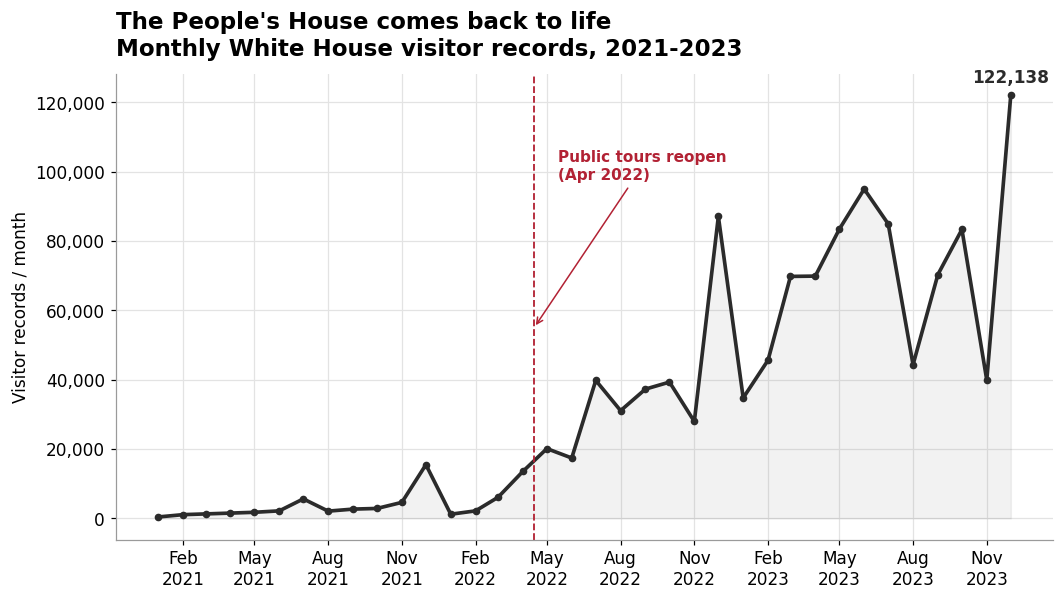

In [ ]:
# --- Monthly total line plot --------------------------------------------

# Create the figure and axis
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["Total"], color=TOTAL, lw=2.4, marker="o", ms=4)
ax.fill_between(monthly.index, monthly["Total"], color=TOTAL, alpha=0.06)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("The People's House comes back to life\nMonthly White House visitor records, 2021-2023")
ax.set_ylabel("Visitor records / month")

# Highlight the reopening date
reopen = pd.Timestamp("2022-04-15")
ax.axvline(reopen, color=FLAG, ls="--", lw=1.2)
ax.annotate("Public tours reopen\n(Apr 2022)", xy=(reopen, monthly["Total"].max()*0.45),
            xytext=(pd.Timestamp("2022-05-15"), monthly["Total"].max()*0.80),
            color=FLAG, fontsize=10, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=FLAG))
# Highlight the peak visitation date
peak = monthly["Total"].idxmax()
ax.annotate(f"{int(monthly['Total'].max()):,}", xy=(peak, monthly["Total"].max()),
            xytext=(0, 8), textcoords="offset points", ha="center",
            fontweight="bold", color=TOTAL)
# Set the x-axis locator and formatter
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.savefig("figures/01_monthly_total_line.png"); plt.show()


## Visual 2 | Stacked bars over time: what's driving the growth
Splitting each month into **official business** vs **public tours** shows tours are the engine of the surge.

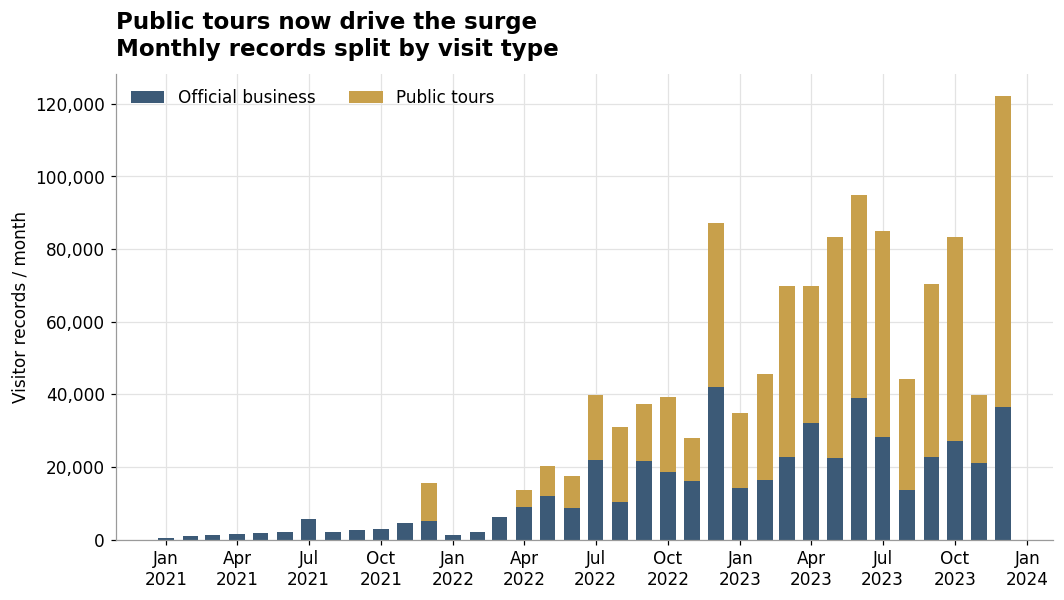

In [ ]:
# --- Stacked bar plot --------------------------------------------

# Create the figure and axis
fig, ax = plt.subplots()
x = monthly.index
ax.bar(x, monthly["Official Business"], width=20, color=BIZ, label="Official business")
ax.bar(x, monthly["Public Tour"], width=20, bottom=monthly["Official Business"],
       color=TOUR, label="Public tours")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Public tours now drive the surge\nMonthly records split by visit type")
ax.set_ylabel("Visitor records / month")
ax.legend(loc="upper left", ncol=2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.savefig("figures/02_stacked_type_time.png"); plt.show()


## Visual 3 | Column chart: the scale of the rebound
Annual totals make the magnitude unmistakable.

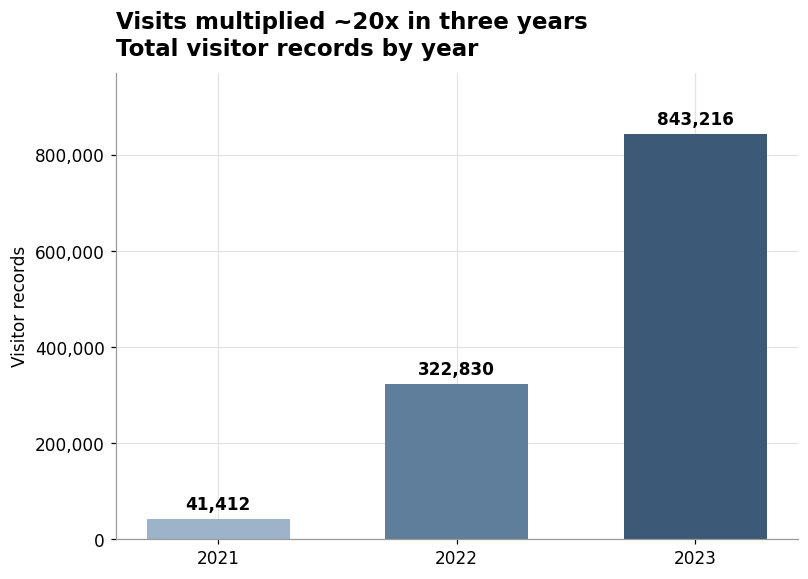

In [ ]:
# --- Yearly column plot --------------------------------------------

# Create the figure and axis
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(yearly.index.astype(str), yearly.values,
              color=["#9CB3C9", "#5E7E9B", BIZ], width=0.6)
ax.bar_label(bars, fmt="{:,.0f}".format, padding=4, fontweight="bold")
ax.yaxis.set_major_formatter(thousands)
mult = yearly.loc[2023] / yearly.loc[2021]
ax.set_title(f"Visits multiplied ~{mult:.0f}x in three years\nTotal visitor records by year")
ax.set_ylabel("Visitor records"); ax.margins(y=0.15)
fig.savefig("figures/03_yearly_column.png"); plt.show()


## Visual 4 | Step chart: cumulative tour visitors
The flat 2021 step is the shutdown made visible; the staircase steepens once tours return.

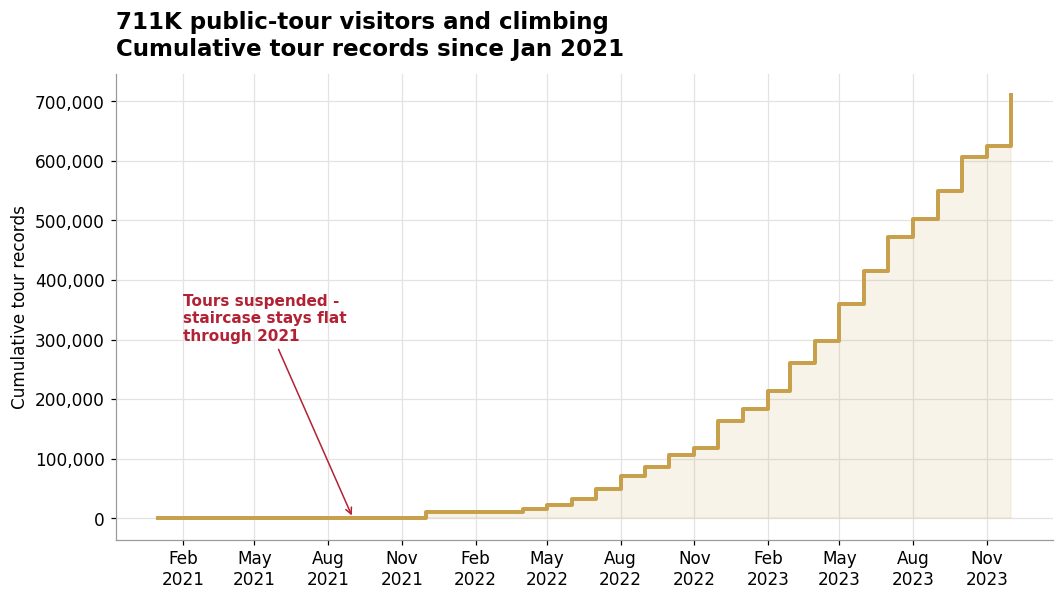

In [ ]:
# --- Cumulative tours step plot --------------------------------------------

# Create the figure and axis
cum = monthly["Public Tour"].cumsum()
total_tours = int(monthly["Public Tour"].sum())
fig, ax = plt.subplots()
ax.step(cum.index, cum.values, where="post", color=TOUR, lw=2.6)
ax.fill_between(cum.index, cum.values, step="post", color=TOUR, alpha=0.12)
ax.yaxis.set_major_formatter(thousands)
ax.set_title(f"{total_tours/1e3:.0f}K public-tour visitors and climbing\nCumulative tour records since Jan 2021")
ax.set_ylabel("Cumulative tour records")
ax.annotate("Tours suspended -\nstaircase stays flat\nthrough 2021",
            xy=(pd.Timestamp("2021-09-01"), cum.loc[:"2021-09-01"].max()),
            xytext=(pd.Timestamp("2021-02-01"), cum.max()*0.42),
            color=FLAG, fontsize=10, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=FLAG))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.savefig("figures/04_cumulative_tours_step.png"); plt.show()


## Visual 5 | Scatterplot over time: day-to-day rhythm
Every dot is a single day. The spread shows how volatile daily demand is — and how tour days now tower over business days.

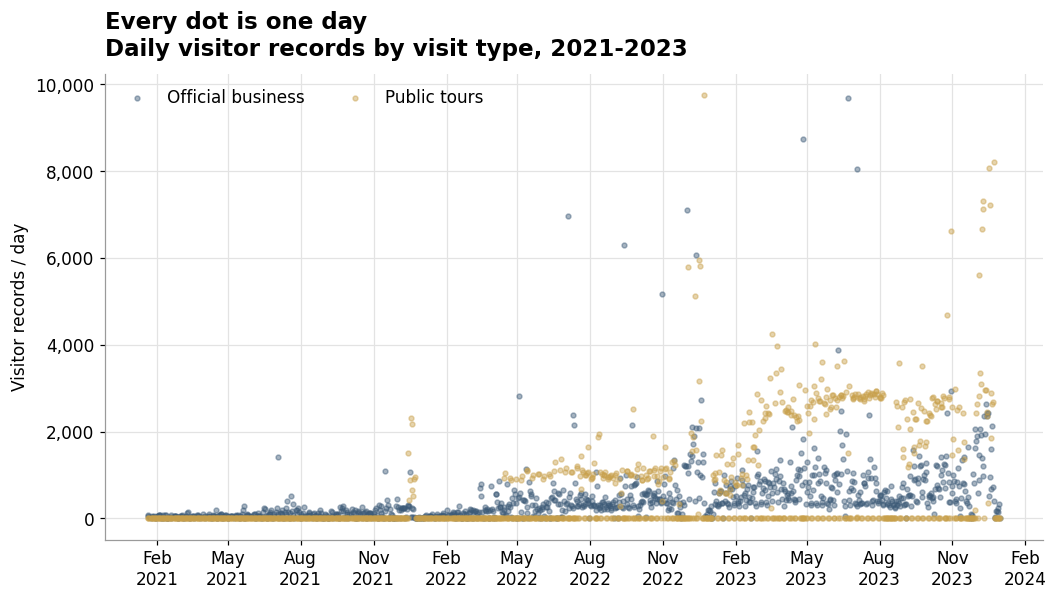

In [ ]:
# --- Daily scatter plot --------------------------------------------

# Create the figure and axis
fig, ax = plt.subplots()
ax.scatter(daily.index, daily["Official Business"], s=10, color=BIZ, alpha=0.45, label="Official business")
ax.scatter(daily.index, daily["Public Tour"], s=10, color=TOUR, alpha=0.45, label="Public tours")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Every dot is one day\nDaily visitor records by visit type, 2021-2023")
ax.set_ylabel("Visitor records / day")
ax.legend(loc="upper left", ncol=2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.savefig("figures/05_daily_scatter_time.png"); plt.show()


## Visual 6 | Column chart: the seasonal pattern behind the ask
Averaging tour volume by calendar month exposes the predictable December (holiday) and summer peaks that staffing should be pre-budgeted for.

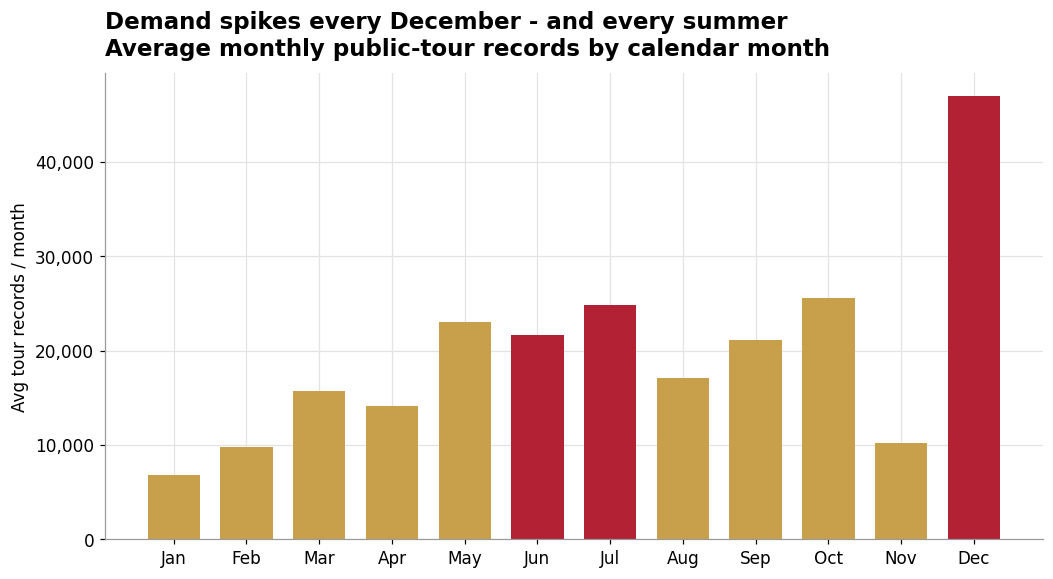

In [ ]:
# --- Seasonality bar plot --------------------------------------------

# Define the labels and calculate seasonal averages
labels = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
season = monthly["Public Tour"].groupby(monthly.index.month).mean()
clr = [FLAG if m in (6,7,12) else TOUR for m in season.index]
# Create the figure and axis
fig, ax = plt.subplots()
ax.bar([labels[m-1] for m in season.index], season.values, color=clr, width=0.72)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Demand spikes every December - and every summer\nAverage monthly public-tour records by calendar month")
ax.set_ylabel("Avg tour records / month")
fig.savefig("figures/06_seasonality_bar.png"); plt.show()


## Visual 7 (supporting) | Bar chart: who keeps the West Wing busy
Among *official business* visits, a handful of staff host the lion's share; useful context for where non-tour capacity is concentrated.

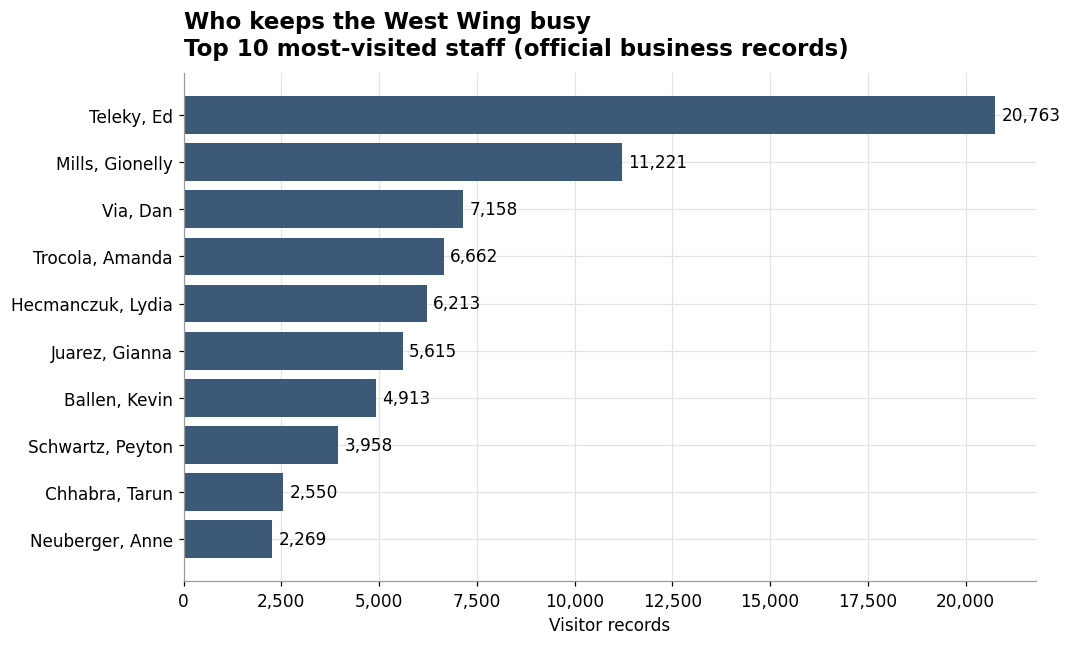

In [ ]:
# --- Top visitees bar plot --------------------------------------------

# Define the labels and calculate top visitees
biz = df[~df["is_tour"]]
name = (biz["visitee_last"].astype(str).str.title().str.strip() + ", "
        + biz["visitee_first"].astype(str).str.title().str.strip())
keep = ~name.str.contains("Nan", na=False) & ~biz["visitee_last"].astype(str).str.fullmatch(r"\d+", na=False)
top = name[keep].value_counts().head(10).iloc[::-1]
# Create the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top.index, top.values, color=BIZ)
ax.bar_label(bars, fmt="{:,.0f}".format, padding=4)
ax.xaxis.set_major_formatter(thousands)
ax.set_title("Who keeps the West Wing busy\nTop 10 most-visited staff (official business records)")
ax.set_xlabel("Visitor records")
fig.savefig("figures/07_top_visitees_barh.png"); plt.show()


---
## Summary & Call to Action

**Audience, purpose, and medium.** This briefing is built for the **White House Visitors Office leadership and Chief Usher's staff**, which is an internal, data-fluent executive audience. Its **purpose is a decision, not a recap**: I ask them to **approve a permanent expansion of weekday public-tour capacity and to pre-budget surge staffing for the November–December and May–July peaks**, rather than re-authorizing capacity month to month. The **medium is a one-page executive briefing/infographic**: six core charts plus a supporting view, sharing one identity, exported to PDF, because executives want the trend and the ask at a glance, with the narrative carried in this short brief.

**Design choices (Gestalt).** A single encoding runs through every chart: 
- gold = public tours
- slate blue = official business
- red = call-outs

*Similarity* and *common fate* let the reader track a category without re-reading legends. *Proximity* groups each chart with its own headline takeaway; consistent left-aligned titles, shared axes, and thousands-formatted numbers give *continuity* and *alignment*. Muted gridlines and generous whitespace create strong *figure–ground* separation, and pre-attentive cues (the red reopening line, highlighted peak months, value labels) direct the eye to the one thing each chart is arguing. Charts progress from *what happened* (line) to *why* (stacked, scale) to *what to do* (seasonality).

**Ethical considerations.** *Changes to the data:* I concatenated 25 monthly files, reconciled two header dialects by column position, parsed dates, and derived a tour-vs-business flag from meeting room and host fields. Crucially, I **counted visitor records rather than summing `TOTAL_PEOPLE`**, which repeats group size on every member's row and would inflate counts severalfold. *Filtering:* I kept only records with a parseable appointment-start date inside 2021–2023; none were silently dropped, and the tour flag is an explicit, stated heuristic that can misclassify edge cases. *Legal/regulatory:* WAVES logs are released under the White House's voluntary disclosure policy and contain real names (PII); I therefore report **only aggregates** and make no claims about individuals. The logs also **exclude** purely personal guests and sensitive/national-security visitors, so they are not a complete census. *Risks:* treating logged visits as total "demand" could over- or under-state need if exclusions shift over time, and the tour heuristic could bias the tour/business split. *Sourcing & credibility:* the data is the official White House release provided for this exercise, acquired ethically as public record. *Mitigation:* I aggregate, label every transformation and assumption, flag the heuristic and the known exclusions, and avoid person-level conclusions.

**The ask, restated:** demand is real, sustained, tour-led, and seasonal. **Lock in the larger tour footprint and staff the predictable peaks now.**
